# BÀI TẬP NHÓM SUY LUẬN THỐNG KÊ (MI3031)
## ĐỀ TÀI: PHÂN TÍCH CHỈ SỐ TÀI CHÍNH CÁC DOANH NGHIỆP THUỘC RỔ S&P 500
### ÁP DỤNG LÝ THUYẾT ƯỚC LƯỢNG ĐIỂM VÀ KHOẢNG TIN CẬY CHO CÁC THAM SỐ TỔNG THỂ

---
- **Môi trường lập trình:** Python (Anaconda Environment: `sltk_project`)
- **Tập dữ liệu sử dụng:** `financials.csv` (S&P 500 Companies with Financial Information)
---


---
## PHẦN 1. MÔ TẢ BỘ DỮ LIỆU & Ý NGHĨA KINH TẾ

### 1.1. Nguồn gốc, Bối cảnh & Ý nghĩa
- **Nguồn dữ liệu:** Bộ dữ liệu [S&P 500 Companies with Financial Information](https://www.kaggle.com/datasets/paytonfisher/sp-500-companies-with-financial-information) thu thập trên Kaggle, ghi nhận thông tin tài chính của các công ty thuộc chỉ số S&P 500 trên thị trường chứng khoán Hoa Kỳ.

- **Bối cảnh kinh tế:**
  - S&P 500 là rổ chỉ số bao gồm hơn 500 công ty đại chúng có vốn hóa thị trường lớn nhất niêm yết tại các sàn giao dịch lớn của Mỹ (NYSE, NASDAQ).
  - Đây là thước đo tiêu chuẩn đại diện cho sức khỏe tài chính và xu hướng định giá của nền kinh tế Mỹ.

- **Xác định tổng thể và mẫu ngẫu nhiên:**
  - **Tổng thể nghiên cứu:** Toàn bộ các tập đoàn / doanh nghiệp quy mô vốn hóa lớn tại Mỹ.
  - **Mẫu ngẫu nhiên:** 505 công ty có trong bộ dữ liệu được coi là một mẫu ngẫu nhiên đại diện được trích xuất từ tổng thể các doanh nghiệp vốn hóa lớn.

### 1.2. Giải thích các khái niệm chuyên ngành
1. **P/E (Price-to-Earnings Ratio):** 
   $$\text{P/E} = \frac{\text{Giá cổ phiếu (Price)}}{\text{Lợi nhuận trên một cổ phiếu (EPS)}}$$

   Chỉ số này phản ánh mức giá mà nhà đầu tư trên thị trường sẵn sàng chi trả cho mỗi 1 đồng (USD) lợi nhuận ròng mà doanh nghiệp tạo ra.

2. **Dividend Yield (Tỷ suất cổ tức):** 
   $$\text{Dividend Yield} = \frac{\text{Cổ tức bằng tiền mặt trả hàng năm trên mỗi cổ phiếu}}{\text{Thị giá cổ phiếu}} \times 100\%$$
   Tỷ suất lợi tức tiền mặt mà nhà đầu tư nhận được trực tiếp từ việc sở hữu cổ phiếu.

3. **Market Cap (Vốn hóa thị trường):** 

    $$\text{Market Cap} = \text{Giá cổ phiếu} \times \text{Số lượng cổ phiếu lưu hành} $$

    Tổng giá trị thị trường của toàn bộ lượng cổ phiếu đang lưu hành của doanh nghiệp

4. **EBITDA:** Lợi nhuận trước lãi vay, thuế và khấu hao — đo lường năng lực tạo dòng tiền từ hoạt động kinh doanh cốt lõi.

5. **Sector (Ngành nghề hoạt động):** Phân loại lĩnh vực kinh doanh chính của doanh nghiệp (ví dụ: Information Technology, Health Care, Financials, Industrials,...).

### 1.3. Bảng phân loại các biến sử dụng trong bài

| Tên biến | Loại biến | Vai trò trong nghiên cứu |
|---|---|---|
| `Price/Earnings` | **Định lượng liên tục** | Biến chính để ước lượng kỳ vọng (3a), phương sai (3b) và so sánh ngành (3d) |
| `Market Cap` | **Định lượng liên tục** | Biến định lượng thứ 2 thể hiện quy mô vốn hóa (USD) |
| `Pay_Dividend` | **Định tính (nhị phân)** | Biến nhị phân nhận giá trị $1$ (Có trả cổ tức) và $0$ (Không trả cổ tức) dùng cho câu 3c |
| `Sector` | **Định tính (danh mục)** | Biến phân nhóm kinh tế để lọc 2 nhóm ngành độc lập: *Information Technology* và *Health Care* (3d) |


In [ ]:

# PHẦN 0: KHỞI TẠO MÔI TRƯỜNG & NẠP DỮ LIỆU


import pandas as pd
import numpy as np
import math
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị đồ thị và định dạng số thực
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Đọc tập dữ liệu
df_raw = pd.read_csv('financials.csv')

print(f"-> Nạp dữ liệu thành công!")
print(f"-> Kích thước tập dữ liệu ban đầu: {df_raw.shape[0]} quan sát (công ty), {df_raw.shape[1]} thuộc tính.")
display(df_raw.head())
print("\nThông tin tổng quát các cột:")
df_raw.info()


-> Nạp dữ liệu thành công!
-> Kích thước tập dữ liệu ban đầu: 505 quan sát (công ty), 14 thuộc tính.


,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
0,MMM,3M Company,Industrials,222.8900,24.3100,2.3329,7.9200,259.7700,175.4900,138721055226.0000,9048000000.0000,4.3903,11.3400,http://www.sec.gov/cgi-bin/browse-edgar?action...
1,AOS,A.O. Smith Corp,Industrials,60.2400,27.7600,1.1480,1.7000,68.3900,48.9250,10783419933.0000,601000000.0000,3.5755,6.3500,http://www.sec.gov/cgi-bin/browse-edgar?action...
2,ABT,Abbott Laboratories,Health Care,56.2700,22.5100,1.9090,0.2600,64.6000,42.2800,102121042306.0000,5744000000.0000,3.7405,3.1900,http://www.sec.gov/cgi-bin/browse-edgar?action...
3,ABBV,AbbVie Inc.,Health Care,108.4800,19.4100,2.4996,3.2900,125.8600,60.0500,181386347059.0000,10310000000.0000,6.2916,26.1400,http://www.sec.gov/cgi-bin/browse-edgar?action...
4,ACN,Accenture plc,Information Technology,150.5100,25.4700,1.7145,5.4400,162.6000,114.8200,98765855553.0000,5643228000.0000,2.6041,10.6200,http://www.sec.gov/cgi-bin/browse-edgar?action...



Thông tin tổng quát các cột:
<class 'pandas.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Symbol          505 non-null    str    
 1   Name            505 non-null    str    
 2   Sector          505 non-null    str    
 3   Price           505 non-null    float64
 4   Price/Earnings  503 non-null    float64
 5   Dividend Yield  505 non-null    float64
 6   Earnings/Share  505 non-null    float64
 7   52 Week Low     505 non-null    float64
 8   52 Week High    505 non-null    float64
 9   Market Cap      505 non-null    float64
 10  EBITDA          505 non-null    float64
 11  Price/Sales     505 non-null    float64
 12  Price/Book      497 non-null    float64
 13  SEC Filings     505 non-null    str    
dtypes: float64(10), str(4)
memory usage: 55.4 KB


In [ ]:

# TIỀN XỬ LÝ DỮ LIỆU


# 1. Khảo sát các vấn đề bất thường của dữ liệu P/E ban đầu
n_total = len(df_raw)
n_missing_pe = df_raw['Price/Earnings'].isna().sum()
n_neg_pe = (df_raw['Price/Earnings'] <= 0).sum()
n_outliers_pe = (df_raw['Price/Earnings'] > 100).sum()

print("--- KHẢO SÁT CHẤT LƯỢNG DỮ LIỆU BAN ĐẦU ---")
print(f"Tổng số quan sát ban đầu: {n_total}")
print(f"1. Số dòng bị missing (NaN) ở cột Price/Earnings : {n_missing_pe} dòng ({n_missing_pe/n_total*100:.2f}%)")
print(f"2. Số dòng có Price/Earnings <= 0 (công ty thua lỗ) : {n_neg_pe} dòng ({n_neg_pe/n_total*100:.2f}%)")
print(f"3. Số dòng có Price/Earnings > 100 (điểm ngoại lai) : {n_outliers_pe} dòng ({n_outliers_pe/n_total*100:.2f}%)")

# 2. Tạo tập dữ liệu sạch cho các bài toán phân tích P/E (3a, 3b, 3d)
df_clean = df_raw[(df_raw['Price/Earnings'] > 0) & (df_raw['Price/Earnings'] <= 100)].copy()

# 3. Tạo biến nhị phân Pay_Dividend trên TOÀN BỘ 505 dòng gốc cho bài toán 3c
# Pay_Dividend = 1 nếu Dividend Yield > 0 (có trả cổ tức), = 0 nếu Dividend Yield == 0
df_raw['Pay_Dividend'] = (df_raw['Dividend Yield'] > 0).astype(int)

# Thêm biến logarit Y = ln(P/E) để phục vụ ước lượng chuẩn hóa
df_clean['Log_PE'] = np.log(df_clean['Price/Earnings'])

print("\n--- KẾT QUẢ SAU TIỀN XỬ LÝ ---")
print(f"Cỡ mẫu sau khi làm sạch để phân tích P/E: n = {len(df_clean)} công ty")
print(f"Cỡ mẫu giữ nguyên để phân tích tỷ lệ trả cổ tức: n = {len(df_raw)} công ty")

# Bảng thống kê mô tả 5 số tóm tắt của P/E sau lọc
display(df_clean[['Price/Earnings', 'Log_PE', 'Market Cap']].describe().T)


--- KHẢO SÁT CHẤT LƯỢNG DỮ LIỆU BAN ĐẦU ---
Tổng số quan sát ban đầu: 505
1. Số dòng bị missing (NaN) ở cột Price/Earnings : 2 dòng (0.40%)
2. Số dòng có Price/Earnings <= 0 (công ty thua lỗ) : 11 dòng (2.18%)
3. Số dòng có Price/Earnings > 100 (điểm ngoại lai) : 12 dòng (2.38%)

--- KẾT QUẢ SAU TIỀN XỬ LÝ ---
Cỡ mẫu sau khi làm sạch để phân tích P/E: n = 480 công ty
Cỡ mẫu giữ nguyên để phân tích tỷ lệ trả cổ tức: n = 505 công ty


,count,mean,std,min,25%,50%,75%,max
Price/Earnings,480.0000,21.7195,10.9550,4.7000,15.3825,19.4500,25.0825,84.3900
Log_PE,480.0000,2.9825,0.4240,1.5476,2.7332,2.9678,3.2222,4.4354
Market Cap,480.0000,48849577705.4479,87343997811.4772,2626102121.0000,12720183431.0000,21467210930.0000,45486250550.2500,809508034020.0000


### 1.4. Lý giải các quyết định tiền xử lý dữ liệu
1. **Loại bỏ dữ liệu `Price/Earnings` bị khuyết thiếu (2 dòng - 0.4%):**
   - Tỷ lệ thiếu cực nhỏ (< 0.4%), việc loại bỏ trực tiếp hoàn toàn không làm sai lệch tính đại diện của mẫu, đồng thời tránh rủi ro áp đặt giả định thiên lệch khi gán giá trị nhân tạo.
2. **Loại bỏ các dòng có `Price/Earnings <= 0` (11 dòng):**
   - *Bản chất tài chính:* Vì thị giá $P > 0$, $P/E \le 0$ chỉ xảy ra khi doanh nghiệp bị thua lỗ hoặc hòa vốn ($EPS \le 0$). Chỉ số P/E đo lường mức giá trả cho 1 đồng lợi nhuận; khi doanh nghiệp không có lãi, chỉ số này mất ý nghĩa định giá.
   - *Bản chất thống kê:* Dữ liệu gốc có P/E âm tới $-251.53$, làm đảo lộn thứ bậc so sánh (lỗ nặng lại có giá trị số học lớn hơn lỗ nhẹ) và kéo sụt trung bình mẫu một cách phi lý. Theo chuẩn mực quốc tế (Bloomberg, S&P Dow Jones), P/E của công ty thua lỗ đều được loại bỏ khi tính mức định giá thị trường.
3. **Loại bỏ các điểm ngoại lai `Price/Earnings > 100` (12 dòng):**
   - P/E > 100 thường do lợi nhuận nhất thời sụt giảm sát 0 khiến mẫu số tí hon hoặc do đầu cơ bong bóng, tạo ra các ngoại lai cực đoan kéo lệch đuôi phải nghiêm trọng và làm méo mó kỳ vọng mẫu.
4. **Sử dụng toàn bộ 505 công ty cho bài toán 3c (Tỷ lệ trả cổ tức):**
   - *Tránh sai lệch chọn mẫu (Selection Bias):* Các công ty thua lỗ hay có P/E cao vẫn có chính sách cổ tức rõ ràng (thường là không trả cổ tức). Nếu loại các công ty này ra trước, ta vô tình loại nhóm ít trả cổ tức nhất, khiến tỷ lệ $\hat{p}$ bị thổi phồng giả tạo.
   - *Đặc trưng biến Bernoulli:* Biến `Pay_Dividend` nhận giá trị $\{0, 1\}$, không có ngoại lai cực trị làm méo phân phối và có đầy đủ dữ liệu 505/505 công ty.

---
## PHẦN 2: BÀI TOÁN 3a — KHOẢNG TIN CẬY 95% CHO KỲ VỌNG P/E ($\mu$)

### 2.1. Cơ sở lý thuyết & Thiết kế bài toán
- **Mục tiêu:** Ước lượng mức định giá P/E kỳ vọng ($\mu$) của các doanh nghiệp vốn hóa lớn tại Mỹ.
- **Biến làm việc:** `Price/Earnings` (sau khi lọc, cỡ mẫu $n = 480$).
- **Cơ sở lý thuyết:**
  - Gọi $X$ là biến ngẫu nhiên đo mức P/E của một doanh nghiệp trong tổng thể, có kỳ vọng $E(X) = \mu$ và phương sai $V(X) = \sigma^2$ (chưa biết).
  - Ước lượng điểm: Trung bình mẫu $\bar{X} = \frac{1}{n}\sum_{i=1}^n X_i$ là ước lượng không chệch của $\mu$; phương sai mẫu hiệu chỉnh $S^2 = \frac{1}{n-1}\sum_{i=1}^n (X_i - \bar{X})^2$ là ước lượng không chệch của $\sigma^2$.
  - Do chưa biết $\sigma^2$, thống kê chuẩn hóa tuân theo phân phối Student:
    $$T = \frac{\bar{X} - \mu}{S / \sqrt{n}} \sim t(n-1)$$
  - **Định lý giới hạn trung tâm (CLT):** Do cỡ mẫu $n = 480 \ge 30$ rất lớn, trung bình mẫu $\bar{X}$ tiệm cận phân phối chuẩn và thống kê Student tiệm cận chuẩn tắc ($t_{479, 0.025} \approx z_{0.025} = 1.96$), đảm bảo điều kiện áp dụng công thức khoảng tin cậy.
- **Công thức khoảng tin cậy 95% cho $\mu$:**
  $$\bar{x} \pm t_{n-1,\, \alpha/2} \cdot \frac{s}{\sqrt{n}}$$
  với mức ý nghĩa $\alpha = 0.05$ (độ tin cậy $95\%$), sai số chuẩn $SE = \frac{s}{\sqrt{n}}$, và biên sai số $ME = t_{n-1,\, \alpha/2} \cdot SE$.

In [ ]:

# BÀI TOÁN 3a: TÍNH TOÁN KHOẢNG TIN CẬY 95% CHO KỲ VỌNG μ
# (Triển khai thủ công bằng công thức toán học, không dùng hàm gói sẵn)


pe_data = df_clean['Price/Earnings'].values
log_pe_data = df_clean['Log_PE'].values
alpha = 0.05

def compute_mean_ci(data, alpha=0.05, label="Data"):
    n = len(data)
    # 1. Trung bình mẫu
    x_bar = sum(data) / n
    # 2. Phương sai mẫu hiệu chỉnh
    s2 = sum((x - x_bar)**2 for x in data) / (n - 1)
    # 3. Độ lệch chuẩn mẫu s
    s = math.sqrt(s2)
    # 4. Sai số chuẩn của trung bình mẫu SE
    se = s / math.sqrt(n)
    # 5. Phân vị Student
    t_crit = stats.t.ppf(1 - alpha/2, df=n - 1)
    # 6. Biên sai số Margin of Error (ME)
    me = t_crit * se
    # 7. Khoảng tin cậy
    ci_lower = x_bar - me
    ci_upper = x_bar + me
    
    return {
        'Biến': label,
        'Cỡ mẫu (n)': n,
        'Trung bình mẫu (x_bar)': x_bar,
        'Độ lệch chuẩn mẫu (s)': s,
        'Sai số chuẩn (SE)': se,
        'Phân vị tới hạn (t_crit)': t_crit,
        'Biên sai số (ME)': me,
        'Cận dưới KTC (95%)': ci_lower,
        'Cận trên KTC (95%)': ci_upper
    }

# Tính toán cho P/E gốc
res_pe = compute_mean_ci(pe_data, alpha=0.05, label="P/E gốc")

# Tính toán song song cho ln(P/E)
res_log_pe = compute_mean_ci(log_pe_data, alpha=0.05, label="ln(P/E)")

# Bảng so sánh kết quả
df_res_3a = pd.DataFrame([res_pe, res_log_pe])
display(df_res_3a)

# Chuyển đổi ngược KTC của ln(P/E) về thang đo P/E (Geometric Mean & Interval)
geom_mean = math.exp(res_log_pe['Trung bình mẫu (x_bar)'])
geom_ci_lower = math.exp(res_log_pe['Cận dưới KTC (95%)'])
geom_ci_upper = math.exp(res_log_pe['Cận trên KTC (95%)'])

print(f"\n-> KTC 95% cho kỳ vọng μ của P/E gốc: [{res_pe['Cận dưới KTC (95%)']:.4f} ; {res_pe['Cận trên KTC (95%)']:.4f}]")
print(f"-> KTC 95% cho kỳ vọng μ_Y của ln(P/E): [{res_log_pe['Cận dưới KTC (95%)']:.4f} ; {res_log_pe['Cận trên KTC (95%)']:.4f}]")
print(f"-> Chuyển đổi ngược KTC logarit (Trung bình nhân): {geom_mean:.4f}, KTC 95% = [{geom_ci_lower:.4f} ; {geom_ci_upper:.4f}]")


,Biến,Cỡ mẫu (n),Trung bình mẫu (x_bar),Độ lệch chuẩn mẫu (s),Sai số chuẩn (SE),Phân vị tới hạn (t_crit),Biên sai số (ME),Cận dưới KTC (95%),Cận trên KTC (95%)
0,P/E gốc,480,21.7195,10.9550,0.5000,1.9649,0.9825,20.7370,22.7020
1,ln(P/E),480,2.9825,0.4240,0.0194,1.9649,0.0380,2.9445,3.0205



-> KTC 95% cho kỳ vọng μ của P/E gốc: [20.7370 ; 22.7020]
-> KTC 95% cho kỳ vọng μ_Y của ln(P/E): [2.9445 ; 3.0205]
-> Chuyển đổi ngược KTC logarit (Trung bình nhân): 19.7366, KTC 95% = [19.0002 ; 20.5015]


### 2.2. Diễn giải kết quả kinh tế & Đánh giá phương pháp

1. **Diễn giải theo ngữ cảnh kinh tế:**
   - Với độ tin cậy 95%, hệ số định giá P/E trung bình của các doanh nghiệp vốn hóa lớn tại Mỹ nằm trong khoảng **$[20.7370 \;;\; 22.7020]$**.
   - *Ý nghĩa thực tiễn:* Thị trường chứng khoán Hoa Kỳ đang chấp nhận trả mức giá trung bình từ **20.74 đến 22.70 USD** cho mỗi 1 USD lợi nhuận ròng hàng năm mà một doanh nghiệp S&P 500 tạo ra. Đây là mức định giá phản ánh sự tin tưởng cao vào năng lực sinh lời dài hạn của các tập đoàn lớn.

2. **So sánh với biến đổi logarit $\ln(P/E)$ & Hạn chế khi giữ nguyên P/E gốc:**
   - Khi chuyển đổi sang thang đo logarit $\ln(P/E)$, trung bình nhân thu được là **$19.7366$** với KTC 95% là **$[19.0002 \;;\; 20.5015]$**.
   - *Hạn chế của P/E gốc:* Do dữ liệu P/E gốc bị lệch phải nhẹ (skewness = 2.51), giá trị trung bình cộng $\bar{x} = 21.72$ bị kéo nhích lên so với trung vị thực tế. Tuy nhiên, nhờ cỡ mẫu lớn $n = 480 \gg 30$, theo Định lý giới hạn trung tâm (CLT), trung bình mẫu $\bar{X}$ vẫn tuân theo phân phối chuẩn xấp xỉ rất tốt, đảm bảo khoảng tin cậy của kỳ vọng $\mu$ hoàn toàn có giá trị thực tiễn.


---
## PHẦN 3: BÀI TOÁN 3b — KHOẢNG TIN CẬY 95% CHO PHƯƠNG SAI P/E ($\sigma^2$)

### 3.1. Cơ sở lý thuyết & Thiết kế bài toán
- **Mục tiêu:** Ước lượng mức độ phân tán định giá (phương sai tổng thể $\sigma^2$ và độ lệch chuẩn $\sigma$) của hệ số P/E.
- **Biến làm việc:** `Price/Earnings` (sau lọc, $n = 480$).
- **Cơ sở lý thuyết:**
  - Khi tổng thể có phân phối chuẩn $X \sim N(\mu, \sigma^2)$, thống kê:
    $$K^2 = \frac{(n-1)S^2}{\sigma^2} \sim \chi^2(n-1)$$
  - Khoảng tin cậy hai phía 95% cho phương sai $\sigma^2$:
    $$\left[ \frac{(n-1)s^2}{\chi^2_{\alpha/2, \, n-1}} \;; \; \frac{(n-1)s^2}{\chi^2_{1-\alpha/2, \, n-1}} \right]$$
  - Lấy căn bậc hai hai cận ta được khoảng tin cậy cho độ lệch chuẩn $\sigma$.
- **Điều kiện áp dụng:** Công thức KTC cho phương sai bắt buộc tổng thể phải có phân phối chuẩn (CLT không áp dụng cho thống kê phương sai). Do đó, cần kiểm tra tính chuẩn qua Histogram và Q-Q plot. Vì P/E có chặn dưới tại 0 và lệch phải (đặc trưng phân phối Log-chuẩn), việc lấy logarit $Y = \ln(P/E)$ giúp chuẩn hóa phân phối để đối chiếu độ tin cậy.


### 3.2. Giải thích công cụ trực quan hóa & Lập luận phương pháp biến đổi

1. **Histogram (Biểu đồ tần số) & Q-Q Plot (Quantile-Quantile Plot):**
   - *Histogram:* Chia dải giá trị thành các khoảng (bins) và đếm tần số, vẽ kèm đường mật độ lý thuyết chuẩn để quan sát độ lệch và đuôi của phân phối.
   - *Q-Q Plot:* So sánh các phân vị thực nghiệm của mẫu với các phân vị lý thuyết của phân phối chuẩn tắc $N(0, 1)$. Nếu các điểm dữ liệu nằm thẳng hàng bám sát đường 45°, dữ liệu chuẩn; nếu uốn cong ở hai đầu, dữ liệu bị lệch đuôi nặng.
2. **Tại sao chọn phép biến đổi logarit $\ln(P/E)$?**
   - Biến P/E có chặn dưới tại 0 ($P/E > 0$) và có đuôi kéo dài sang phải $\implies$ đặc trưng điển hình của **phân phối Log-chuẩn (Lognormal Distribution)**.
   - Lấy logarit $Y = \ln(P/E)$ giúp nén các giá trị cực lớn ở đuôi phải và kéo giãn vùng gần 0, đưa phân phối của $Y$ về dạng gần đối xứng và tiệm cận phân phối chuẩn $N(\mu_Y, \sigma_Y^2)$.
3. **Tại sao không chọn cách khác (ví dụ: khớp phân phối tương ứng như Gamma, Weibull)?**
   - *Phạm vi chương trình học:* Giáo trình chỉ xây dựng công thức KTC giải tích đóng cho phân phối chuẩn ($\chi^2$). Không có công thức giải tích đóng đơn giản cho KTC phương sai của Gamma/Weibull trong giáo trình.
   - *Độ phức tạp toán học:* Ước lượng KTC phương sai cho phân phối Gamma/Weibull đòi hỏi các kỹ thuật nâng cao (Bootstrap tái lấy mẫu, ước lượng tiệm cận ma trận Fisher), vượt quá yêu cầu bài tập cơ bản.
   - *Chuẩn mực tài chính:* Biến đổi logarit là chuẩn mực kinh điển trong phân tích tài chính (log-returns, log-valuation) vì bảo toàn thứ bậc và dễ diễn giải.


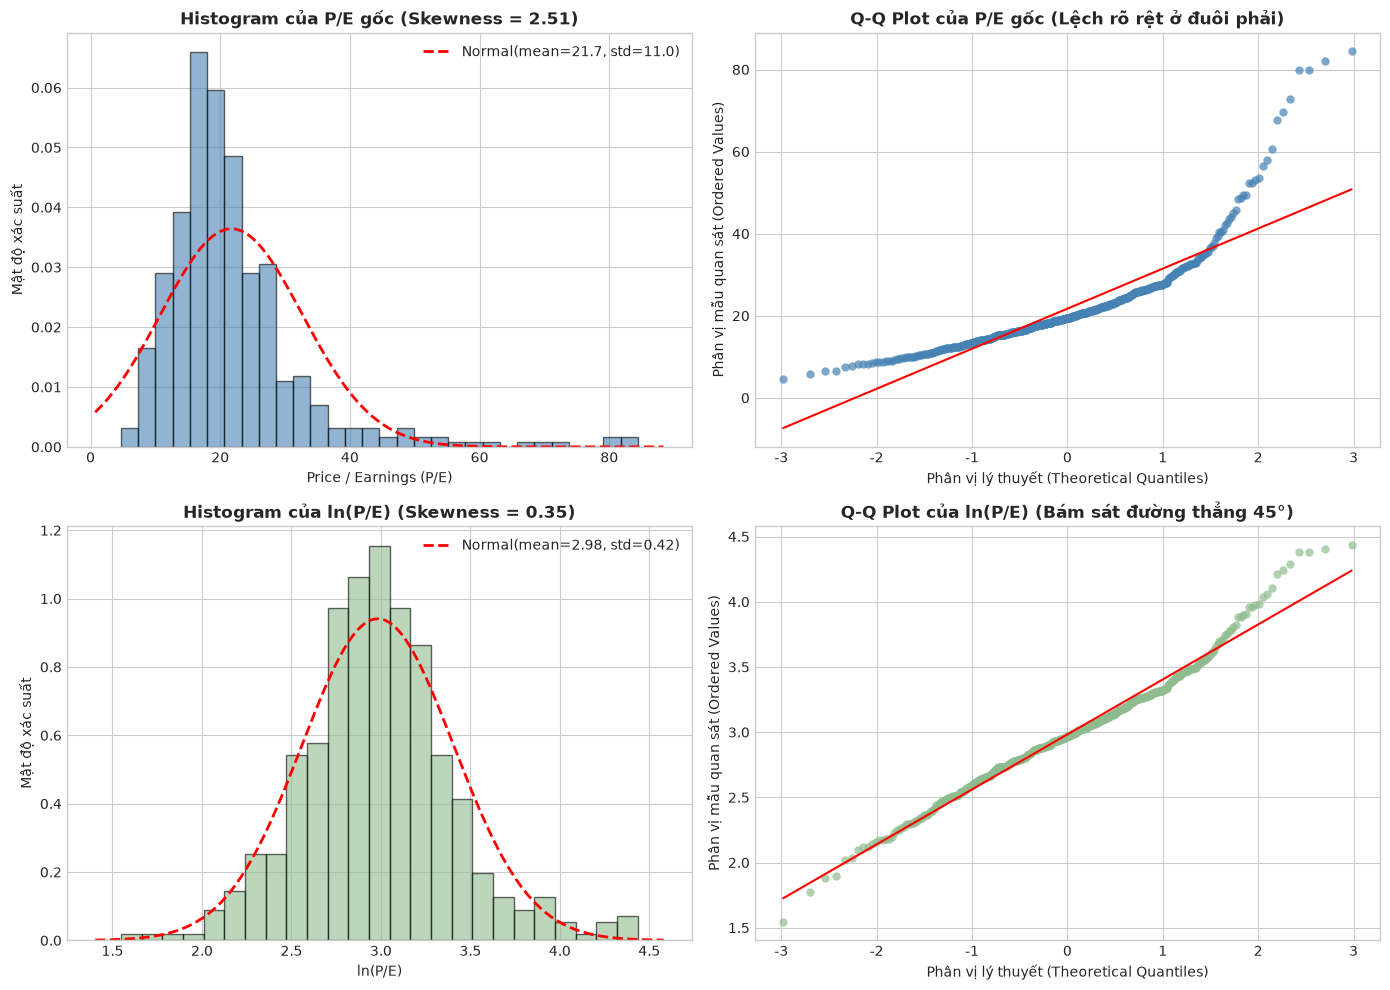

In [ ]:

# TRỰC QUAN HÓA KIỂM TRA TÍNH CHUẨN CỦA P/E VÀ ln(P/E)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram P/E gốc
axes[0, 0].hist(pe_data, bins=30, density=True, alpha=0.6, color='steelblue', edgecolor='black')
# Đường phân phối chuẩn lý thuyết chồng lên
mu_pe, std_pe = np.mean(pe_data), np.std(pe_data, ddof=1)
xmin, xmax = axes[0, 0].get_xlim()
x_norm = np.linspace(xmin, xmax, 200)
axes[0, 0].plot(x_norm, stats.norm.pdf(x_norm, mu_pe, std_pe), 'r--', linewidth=2, label=f'Normal(mean={mu_pe:.1f}, std={std_pe:.1f})')
axes[0, 0].set_title(f"Histogram của P/E gốc (Skewness = {stats.skew(pe_data):.2f})", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Price / Earnings (P/E)")
axes[0, 0].set_ylabel("Mật độ xác suất")
axes[0, 0].legend()

# 2. Q-Q Plot P/E gốc
stats.probplot(pe_data, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_markerfacecolor('steelblue')
axes[0, 1].get_lines()[0].set_markeredgecolor('none')
axes[0, 1].get_lines()[0].set_alpha(0.7)
axes[0, 1].set_title("Q-Q Plot của P/E gốc (Lệch rõ rệt ở đuôi phải)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Phân vị lý thuyết (Theoretical Quantiles)")
axes[0, 1].set_ylabel("Phân vị mẫu quan sát (Ordered Values)")

# 3. Histogram ln(P/E)
axes[1, 0].hist(log_pe_data, bins=25, density=True, alpha=0.6, color='darkseagreen', edgecolor='black')
mu_log, std_log = np.mean(log_pe_data), np.std(log_pe_data, ddof=1)
xmin_l, xmax_l = axes[1, 0].get_xlim()
x_norm_l = np.linspace(xmin_l, xmax_l, 200)
axes[1, 0].plot(x_norm_l, stats.norm.pdf(x_norm_l, mu_log, std_log), 'r--', linewidth=2, label=f'Normal(mean={mu_log:.2f}, std={std_log:.2f})')
axes[1, 0].set_title(f"Histogram của ln(P/E) (Skewness = {stats.skew(log_pe_data):.2f})", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("ln(P/E)")
axes[1, 0].set_ylabel("Mật độ xác suất")
axes[1, 0].legend()

# 4. Q-Q Plot ln(P/E)
stats.probplot(log_pe_data, dist="norm", plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_markerfacecolor('darkseagreen')
axes[1, 1].get_lines()[0].set_markeredgecolor('none')
axes[1, 1].get_lines()[0].set_alpha(0.7)
axes[1, 1].set_title("Q-Q Plot của ln(P/E) (Bám sát đường thẳng 45°)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Phân vị lý thuyết (Theoretical Quantiles)")
axes[1, 1].set_ylabel("Phân vị mẫu quan sát (Ordered Values)")

plt.tight_layout()
plt.show()


In [ ]:

# BÀI TOÁN 3b: TÍNH TOÁN KHOẢNG TIN CẬY 95% CHO PHƯƠNG SAI σ²
# (Tính song song cho P/E gốc và ln(P/E))


def compute_var_ci(data, alpha=0.05, label="Data"):
    n = len(data)
    df_val = n - 1
    # 1. Tính phương sai mẫu hiệu chỉnh s^2
    mean_val = sum(data) / n
    s2 = sum((x - mean_val)**2 for x in data) / df_val
    s = math.sqrt(s2)
    
    # 2. Tra phân vị chi-bình phương (ppf trả về phân vị tích lũy bên trái)
    # chi2_upper tương ứng với chi^2_{alpha/2} trong slide (giá trị lớn, mẫu số cận dưới)
    chi2_upper = stats.chi2.ppf(1 - alpha/2, df=df_val)
    # chi2_lower tương ứng với chi^2_{1-alpha/2} trong slide (giá trị nhỏ, mẫu số cận trên)
    chi2_lower = stats.chi2.ppf(alpha/2, df=df_val)
    
    # 3. Cận khoảng tin cậy cho phương sai sigma^2
    var_lower = df_val * s2 / chi2_upper
    var_upper = df_val * s2 / chi2_lower
    
    # 4. Cận khoảng tin cậy cho độ lệch chuẩn sigma
    std_lower = math.sqrt(var_lower)
    std_upper = math.sqrt(var_upper)
    
    return {
        'Biến': label,
        'Cỡ mẫu (n)': n,
        'Bậc tự do (df)': df_val,
        'Phương sai mẫu (s^2)': s2,
        'Độ lệch chuẩn mẫu (s)': s,
        'chi2_lower (0.025)': chi2_lower,
        'chi2_upper (0.975)': chi2_upper,
        'KTC 95% σ² (Cận dưới)': var_lower,
        'KTC 95% σ² (Cận trên)': var_upper,
        'KTC 95% σ (Cận dưới)': std_lower,
        'KTC 95% σ (Cận trên)': std_upper,
        'Độ lệch (Skewness)': stats.skew(data)
    }

res_var_pe = compute_var_ci(pe_data, alpha=0.05, label="P/E gốc")
res_var_log_pe = compute_var_ci(log_pe_data, alpha=0.05, label="ln(P/E)")

df_res_3b = pd.DataFrame([res_var_pe, res_var_log_pe])
display(df_res_3b.T)

print(f"-> KTC 95% cho phương sai σ² của P/E gốc: [{res_var_pe['KTC 95% σ² (Cận dưới)']:.4f} ; {res_var_pe['KTC 95% σ² (Cận trên)']:.4f}]")
print(f"-> KTC 95% cho độ lệch chuẩn σ của P/E gốc: [{res_var_pe['KTC 95% σ (Cận dưới)']:.4f} ; {res_var_pe['KTC 95% σ (Cận trên)']:.4f}]")
print(f"-> KTC 95% cho phương sai Var(ln(P/E)): [{res_var_log_pe['KTC 95% σ² (Cận dưới)']:.4f} ; {res_var_log_pe['KTC 95% σ² (Cận trên)']:.4f}]")
print(f"-> KTC 95% cho độ lệch chuẩn SD(ln(P/E)): [{res_var_log_pe['KTC 95% σ (Cận dưới)']:.4f} ; {res_var_log_pe['KTC 95% σ (Cận trên)']:.4f}]")


,0,1
Biến,P/E gốc,ln(P/E)
Cỡ mẫu (n),480,480
Bậc tự do (df),479,479
Phương sai mẫu (s^2),120.0111,0.1797
Độ lệch chuẩn mẫu (s),10.9550,0.4240
chi2_lower (0.025),420.2520,420.2520
chi2_upper (0.975),541.5355,541.5355
KTC 95% σ² (Cận dưới),106.1524,0.1590
KTC 95% σ² (Cận trên),136.7877,0.2049
KTC 95% σ (Cận dưới),10.3030,0.3987


-> KTC 95% cho phương sai σ² của P/E gốc: [106.1524 ; 136.7877]
-> KTC 95% cho độ lệch chuẩn σ của P/E gốc: [10.3030 ; 11.6956]
-> KTC 95% cho phương sai Var(ln(P/E)): [0.1590 ; 0.2049]
-> KTC 95% cho độ lệch chuẩn SD(ln(P/E)): [0.3987 ; 0.4526]


### 3.3. Diễn giải kết quả kinh tế & Đánh giá hạn chế
- **Ý nghĩa kinh tế:** Với độ tin cậy 95%, phương sai của hệ số P/E nằm trong khoảng **$[106.1524 \;;\; 136.7877]$**, tương đương độ lệch chuẩn $\sigma \in [10.3030 \;;\; 11.6956]$ đơn vị P/E. Khoảng tin cậy này phản ánh mức độ phân hóa định giá đáng kể giữa các doanh nghiệp trong rổ S&P 500 do sự khác biệt về tiềm năng tăng trưởng giữa các nhóm ngành.
- **Đánh giá hạn chế & Ưu điểm của $\ln(P/E)$:**
  - Dữ liệu P/E gốc có hệ số bất đối xứng $\text{Skewness} = 2.51 > 0$ (lệch phải). Do đó, kết quả KTC cho $\sigma^2$ của P/E gốc mang tính chất tham khảo thực nghiệm vì vi phạm giả thiết phân phối chuẩn.
  - Sau phép biến đổi logarit, hệ số bất đối xứng giảm xuống chỉ còn $\text{Skewness} = 0.35$ (tiệm cận chuẩn), giúp KTC cho phương sai $\text{Var}(\ln(P/E)) \in [0.1590 \;;\; 0.2049]$ đạt độ tin cậy toán học vững chắc.


---
## PHẦN 4: BÀI TOÁN 3c — KHOẢNG TIN CẬY 95% CHO TỶ LỆ TRẢ CỔ TỨC ($p$)

### 4.1. Cơ sở lý thuyết & Thiết kế bài toán
- **Mục tiêu:** Ước lượng tỷ lệ $p$ — xác suất một doanh nghiệp vốn hóa lớn tại Mỹ duy trì chính sách chi trả cổ tức tiền mặt cho cổ đông.
- **Biến làm việc:** `Pay_Dividend` (1 nếu có trả cổ tức, 0 nếu không trả), tính trên toàn bộ 505 doanh nghiệp gốc để tránh sai lệch chọn mẫu.
- **Cơ sở lý thuyết:**
  - Biến ngẫu nhiên $X_i \sim \text{Bernoulli}(p)$ với $E(X_i) = p, V(X_i) = p(1-p)$.
  - Tần suất mẫu: $\hat{p} = \frac{k}{n} = \frac{1}{n}\sum_{i=1}^n X_i$.
  - Khi cỡ mẫu lớn, theo Định lý giới hạn trung tâm:
    $$Z = \frac{\hat{p} - p}{\sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}} \sim N(0, 1)$$
  - **Kiểm tra điều kiện xấp xỉ chuẩn:** $n\hat{p} = 419 \ge 5$ và $n(1 - \hat{p}) = 86 \ge 5$ $\implies$ Thỏa mãn điều kiện xấp xỉ chuẩn.
- **Công thức khoảng tin cậy 95% cho $p$:**
  $$\hat{p} \pm z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$$
  với $z_{\alpha/2} = z_{0.025} \approx 1.96$.


--- KẾT QUẢ TÍNH TOÁN KTC CHO TỶ LỆ TRẢ CỔ TỨC ---
Tổng số quan sát (n): 505
Số doanh nghiệp có trả cổ tức (k): 419
Tỷ lệ mẫu (p_hat): 0.8297 (82.97%)
Kiểm tra điều kiện: n*p_hat = 419.0 >= 5 ; n*(1-p_hat) = 86.0 >= 5 -> THỎA MÃN
Sai số chuẩn (SE): 0.0167
Phân vị chuẩn tắc (z_0.025): 1.9600
Biên sai số (ME): 0.0328 (3.28%)
KTC 95% cho tỷ lệ p: [0.7969 ; 0.8625]  hay  [79.69% ; 86.25%]


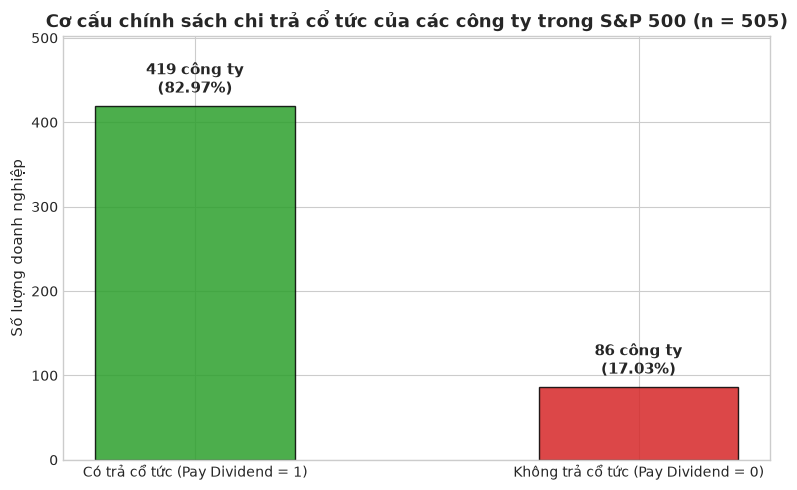

In [ ]:

# BÀI TOÁN 3c: TÍNH TOÁN KHOẢNG TIN CẬY 95% CHO TỶ LỆ TRẢ CỔ TỨC p
# VÀ TRỰC QUAN HÓA BẰNG BIỂU ĐỒ CỘT (BAR CHART)


# 1. Tính toán trên toàn bộ 505 dòng gốc
n_all = len(df_raw)
k_div = df_raw['Pay_Dividend'].sum()
p_hat = k_div / n_all
alpha = 0.05

# 2. Kiểm tra điều kiện xấp xỉ chuẩn
np_val = n_all * p_hat
nq_val = n_all * (1 - p_hat)

# 3. Tra phân vị chuẩn tắc z_{alpha/2}
z_crit = stats.norm.ppf(1 - alpha/2) # 1.95996...

# 4. Sai số chuẩn và biên sai số
se_p = math.sqrt(p_hat * (1 - p_hat) / n_all)
me_p = z_crit * se_p

# 5. Khoảng tin cậy 95%
p_lower = p_hat - me_p
p_upper = p_hat + me_p

print("--- KẾT QUẢ TÍNH TOÁN KTC CHO TỶ LỆ TRẢ CỔ TỨC ---")
print(f"Tổng số quan sát (n): {n_all}")
print(f"Số doanh nghiệp có trả cổ tức (k): {k_div}")
print(f"Tỷ lệ mẫu (p_hat): {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Kiểm tra điều kiện: n*p_hat = {np_val:.1f} >= 5 ; n*(1-p_hat) = {nq_val:.1f} >= 5 -> THỎA MÃN")
print(f"Sai số chuẩn (SE): {se_p:.4f}")
print(f"Phân vị chuẩn tắc (z_0.025): {z_crit:.4f}")
print(f"Biên sai số (ME): {me_p:.4f} ({me_p*100:.2f}%)")
print(f"KTC 95% cho tỷ lệ p: [{p_lower:.4f} ; {p_upper:.4f}]  hay  [{p_lower*100:.2f}% ; {p_upper*100:.2f}%]")

# 6. Trực quan hóa bằng Biểu đồ cột (Bar Chart)
fig, ax = plt.subplots(figsize=(8, 5))

categories = ['Có trả cổ tức (Pay Dividend = 1)', 'Không trả cổ tức (Pay Dividend = 0)']
counts = [k_div, n_all - k_div]
percentages = [p_hat * 100, (1 - p_hat) * 100]
colors = ['#2ca02c', '#d62728']

bars = ax.bar(categories, counts, color=colors, alpha=0.85, width=0.45, edgecolor='black')

# Hiển thị số lượng và phần trăm trên đầu mỗi cột
for bar, count, pct in zip(bars, counts, percentages):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 10,
            f"{count} công ty\n({pct:.2f}%)",
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylim(0, max(counts) * 1.2)
ax.set_title("Cơ cấu chính sách chi trả cổ tức của các công ty trong S&P 500 (n = 505)", fontsize=13, fontweight='bold')
ax.set_ylabel("Số lượng doanh nghiệp", fontsize=11)
plt.tight_layout()
plt.show()


### 4.2. Diễn giải kết quả kinh tế
- **Kết quả:** Với độ tin cậy 95%, tỷ lệ các doanh nghiệp vốn hóa lớn tại Mỹ duy trì chính sách chi trả cổ tức tiền mặt cho cổ đông nằm trong khoảng từ **$79.69\%$ đến $86.25\%$** (tức $\hat{p} = 82.97\% \pm 3.28\%$).
- **Ý nghĩa kinh tế:** Toàn bộ khoảng tin cậy đều nằm ở mức rất cao ($> 79\%$), khẳng định đại đa số các tập đoàn lớn của nền kinh tế Mỹ đều coi trọng việc chia sẻ dòng tiền lợi nhuận trực tiếp bằng cổ tức tiền mặt cho cổ đông. Khoảng $17\%$ doanh nghiệp không trả cổ tức chủ yếu là các công ty trong giai đoạn tăng trưởng mạnh (giữ lại lợi nhuận để đầu tư R&D và mở rộng kinh doanh).


---
## PHẦN 5: BÀI TOÁN 3d — KHOẢNG TIN CẬY 95% CHO HIỆU KỲ VỌNG P/E GIỮA HAI NGÀNH ($\mu_1 - \mu_2$)

### 5.1. Cơ sở lý thuyết & Thiết kế bài toán
- **Mục tiêu:** So sánh mức định giá P/E trung bình giữa ngành **Công nghệ thông tin** (Information Technology - nhóm 1) và **Chăm sóc sức khỏe** (Health Care - nhóm 2).
- **Dữ liệu phân nhóm:**
  - Nhóm 1 (IT): $n_1 = 66$ công ty.
  - Nhóm 2 (Health Care): $n_2 = 58$ công ty.
- **Cơ sở lý thuyết:**
  - Hai mẫu ngẫu nhiên độc lập với phương sai $\sigma_1^2, \sigma_2^2$ chưa biết và không giả định bằng nhau.
  - Phân phối mẫu của hiệu trung bình: $E(\bar{X}_1 - \bar{X}_2) = \mu_1 - \mu_2$, $V(\bar{X}_1 - \bar{X}_2) = \frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}$.
  - Do cỡ mẫu cả hai nhóm đều lớn ($n_1 = 66 \ge 30, n_2 = 58 \ge 30$), theo Định lý giới hạn trung tâm (CLT), hiệu hai trung bình mẫu xấp xỉ phân phối chuẩn:
    $$(\bar{x}_1 - \bar{x}_2) \pm z_{\alpha/2} \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$
  - Để đối chiếu thêm, ta tính toán song song theo xấp xỉ Student Welch với bậc tự do Satterthwaite $\nu$:
    $$\nu = \frac{\left(\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1-1} + \frac{(s_2^2/n_2)^2}{n_2-1}}$$


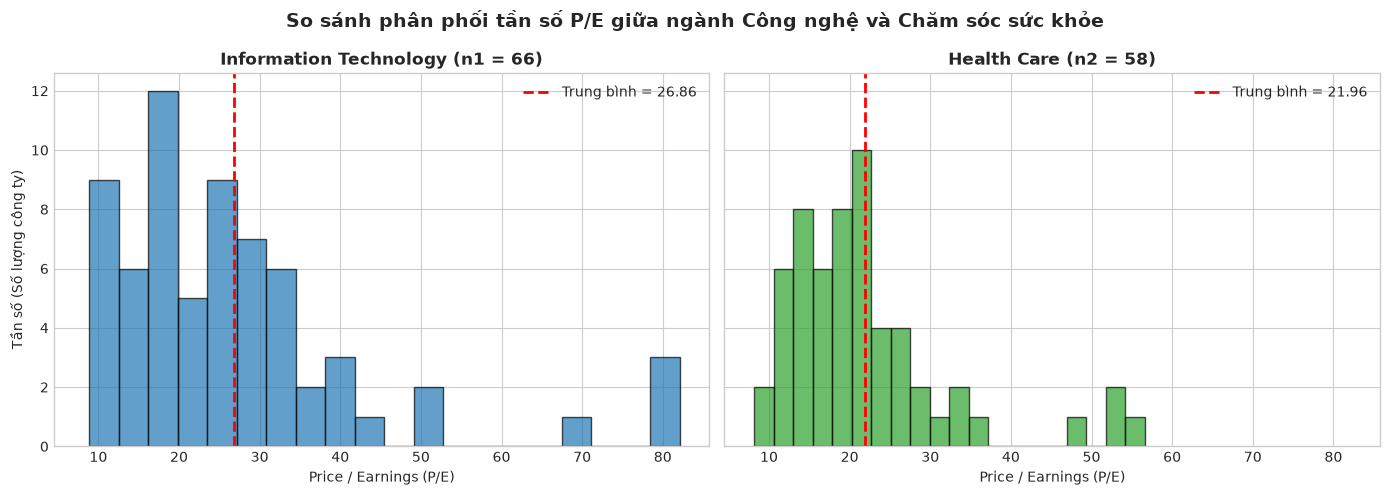

,Chỉ số,Information Technology (Nhóm 1),Health Care (Nhóm 2)
0,Cỡ mẫu (n),66.0000,58.0000
1,Trung bình mẫu (x_bar),26.8550,21.9567
2,Phương sai mẫu (s^2),264.2001,110.2625
3,Độ lệch chuẩn mẫu (s),16.2542,10.5006


In [ ]:

# TRỰC QUAN HÓA SO SÁNH PHÂN PHỐI P/E GIỮA IT VÀ HEALTH CARE BẰNG HISTOGRAM


pe_it = df_clean[df_clean['Sector'] == 'Information Technology']['Price/Earnings'].values
pe_hc = df_clean[df_clean['Sector'] == 'Health Care']['Price/Earnings'].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

# 1. Histogram ngành Information Technology
ax1.hist(pe_it, bins=20, color='#1f77b4', alpha=0.7, edgecolor='black')
ax1.axvline(np.mean(pe_it), color='red', linestyle='--', linewidth=2, label=f'Trung bình = {np.mean(pe_it):.2f}')
ax1.set_title(f"Information Technology (n1 = {len(pe_it)})", fontsize=12, fontweight='bold')
ax1.set_xlabel("Price / Earnings (P/E)")
ax1.set_ylabel("Tần số (Số lượng công ty)")
ax1.legend()

# 2. Histogram ngành Health Care
ax2.hist(pe_hc, bins=20, color='#2ca02c', alpha=0.7, edgecolor='black')
ax2.axvline(np.mean(pe_hc), color='red', linestyle='--', linewidth=2, label=f'Trung bình = {np.mean(pe_hc):.2f}')
ax2.set_title(f"Health Care (n2 = {len(pe_hc)})", fontsize=12, fontweight='bold')
ax2.set_xlabel("Price / Earnings (P/E)")
ax2.legend()

plt.suptitle("So sánh phân phối tần số P/E giữa ngành Công nghệ và Chăm sóc sức khỏe", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# In bảng thống kê mô tả 2 nhóm
desc_compare = pd.DataFrame({
    'Chỉ số': ['Cỡ mẫu (n)', 'Trung bình mẫu (x_bar)', 'Phương sai mẫu (s^2)', 'Độ lệch chuẩn mẫu (s)'],
    'Information Technology (Nhóm 1)': [len(pe_it), np.mean(pe_it), np.var(pe_it, ddof=1), np.std(pe_it, ddof=1)],
    'Health Care (Nhóm 2)': [len(pe_hc), np.mean(pe_hc), np.var(pe_hc, ddof=1), np.std(pe_hc, ddof=1)]
})
display(desc_compare)


In [8]:

# BÀI TOÁN 3d: TÍNH TOÁN KHOẢNG TIN CẬY 95% CHO HIỆU HAI KỲ VỌNG (μ1 - μ2)
# (Đối chiếu giữa xấp xỉ Chuẩn Z và xấp xỉ Student t Welch theo Định lý 13)


n1 = len(pe_it)
x1_bar = sum(pe_it) / n1
s1_sq = sum((x - x1_bar)**2 for x in pe_it) / (n1 - 1)

n2 = len(pe_hc)
x2_bar = sum(pe_hc) / n2
s2_sq = sum((x - x2_bar)**2 for x in pe_hc) / (n2 - 1)

# 1. Hiệu trung bình mẫu
diff = x1_bar - x2_bar

# 2. Sai số chuẩn của hiệu hai trung bình mẫu
se_diff = math.sqrt(s1_sq / n1 + s2_sq / n2)

# 3. Tính toán theo xấp xỉ Chuẩn Z (CLT cho mẫu lớn)
z_crit = stats.norm.ppf(1 - alpha/2)
me_z = z_crit * se_diff
ci_lower_z = diff - me_z
ci_upper_z = diff + me_z

# 4. Tính toán theo phân phối Student Welch (Định lý 13 Chap 2)
# Bậc tự do Satterthwaite nu:
nu_num = (s1_sq / n1 + s2_sq / n2)**2
nu_den = ((s1_sq / n1)**2) / (n1 - 1) + ((s2_sq / n2)**2) / (n2 - 1)
nu = math.floor(nu_num / nu_den)
t_welch = stats.t.ppf(1 - alpha/2, df=nu)
me_welch = t_welch * se_diff
ci_lower_welch = diff - me_welch
ci_upper_welch = diff + me_welch

# 5. Tính toán song song trên biến đổi logarit ln(P/E)
log_pe_it = np.log(pe_it)
log_pe_hc = np.log(pe_hc)
y1_bar = np.mean(log_pe_it)
sy1_sq = np.var(log_pe_it, ddof=1)
y2_bar = np.mean(log_pe_hc)
sy2_sq = np.var(log_pe_hc, ddof=1)
diff_log = y1_bar - y2_bar
se_diff_log = math.sqrt(sy1_sq / n1 + sy2_sq / n2)
me_diff_log = z_crit * se_diff_log

# Bảng tổng hợp so sánh phương pháp
df_res_3d = pd.DataFrame([
    {
        'Phương pháp': 'Xấp xỉ Chuẩn Z (CLT mẫu lớn)',
        'Hiệu trung bình (x1 - x2)': diff,
        'Sai số chuẩn (SE)': se_diff,
        'Hệ số tới hạn': z_crit,
        'Bậc tự do (nu)': 'Tiệm cận vô cùng',
        'Biên sai số (ME)': me_z,
        'Cận dưới KTC (95%)': ci_lower_z,
        'Cận trên KTC (95%)': ci_upper_z
    },
    {
        'Phương pháp': 'Student Welch (Định lý 13)',
        'Hiệu trung bình (x1 - x2)': diff,
        'Sai số chuẩn (SE)': se_diff,
        'Hệ số tới hạn': t_welch,
        'Bậc tự do (nu)': nu,
        'Biên sai số (ME)': me_welch,
        'Cận dưới KTC (95%)': ci_lower_welch,
        'Cận trên KTC (95%)': ci_upper_welch
    },
    {
        'Phương pháp': 'Hiệu ln(P/E) (Chuẩn hóa log)',
        'Hiệu trung bình (x1 - x2)': diff_log,
        'Sai số chuẩn (SE)': se_diff_log,
        'Hệ số tới hạn': z_crit,
        'Bậc tự do (nu)': 'Tiệm cận vô cùng',
        'Biên sai số (ME)': me_diff_log,
        'Cận dưới KTC (95%)': diff_log - me_diff_log,
        'Cận trên KTC (95%)': diff_log + me_diff_log
    }
])
display(df_res_3d)

print(f"-> Theo xấp xỉ chuẩn Z: KTC 95% = [{ci_lower_z:.4f} ; {ci_upper_z:.4f}]")
print(f"-> Theo Student Welch: KTC 95% = [{ci_lower_welch:.4f} ; {ci_upper_welch:.4f}]")
print(f"-> Theo hiệu logarit: KTC 95% = [{diff_log - me_diff_log:.4f} ; {diff_log + me_diff_log:.4f}]")


,Phương pháp,Hiệu trung bình (x1 - x2),Sai số chuẩn (SE),Hệ số tới hạn,Bậc tự do (nu),Biên sai số (ME),Cận dưới KTC (95%),Cận trên KTC (95%)
0,Xấp xỉ Chuẩn Z (CLT mẫu lớn),4.8983,2.4298,1.9600,Tiệm cận vô cùng,4.7624,0.1359,9.6607
1,Student Welch (Định lý 13),4.8983,2.4298,1.9814,112,4.8144,0.0839,9.7127
2,Hiệu ln(P/E) (Chuẩn hóa log),0.1514,0.0850,1.9600,Tiệm cận vô cùng,0.1666,-0.0152,0.3180


-> Theo xấp xỉ chuẩn Z: KTC 95% = [0.1359 ; 9.6607]
-> Theo Student Welch: KTC 95% = [0.0839 ; 9.7127]
-> Theo hiệu logarit: KTC 95% = [-0.0152 ; 0.3180]


### 5.2. Diễn giải kết quả kinh tế & Nhận xét so sánh
- **Phân tích kết quả:** Cả hai phương pháp (xấp xỉ Chuẩn $Z$ và phân phối Student Welch) đều cho kết quả nhất quán:
  - KTC theo xấp xỉ Chuẩn: **$[0.1359 \;;\; 9.6607]$**
  - KTC theo Student Welch: **$[0.0839 \;;\; 9.7127]$**
  - Cả hai cận đều dương ($> 0$), khoảng tin cậy hoàn toàn không chứa giá trị 0. Do đó, ở mức ý nghĩa $\alpha = 0.05$ (độ tin cậy 95%), có đủ bằng chứng thống kê để kết luận: **Mức định giá P/E trung bình của ngành Công nghệ thông tin cao hơn ngành Chăm sóc sức khỏe một cách có ý nghĩa thống kê.**
- **Lý giải kinh tế:** Mức chênh lệch trung bình dao động từ **0.14 đến 9.66 lần P/E**. Điều này hoàn toàn phù hợp với thực tế kinh tế: ngành Công nghệ thông tin có biên lợi nhuận cao và tiềm năng tăng trưởng đột phá nên được thị trường chấp nhận mức định giá cao; trong khi ngành Chăm sóc sức khỏe mang tính phòng thủ cao và doanh thu ổn định, chịu sự kiểm soát chặt chẽ về chi phí và giá thành nên được định giá thận trọng hơn.


---
## PHẦN 6: BẢNG TỔNG HỢP KẾT QUẢ & KẾT LUẬN CHUNG

### 6.1. Bảng tổng hợp kết quả 4 bài toán ước lượng tham số
| Bài toán | Tham số tổng thể | Phương pháp thống kê | Kết quả Khoảng tin cậy 95% | Diễn giải kinh tế ngắn gọn |
|---|---|---|---|---|
| **3a** | Kỳ vọng P/E ($\mu$) | $t$-interval / CLT ($n=480$) | **$[20.7370 \;;\; 22.7020]$** | Nhà đầu tư chấp nhận bỏ ra trung bình 20.74 - 22.70 USD cho 1 USD lợi nhuận doanh nghiệp lớn. |
| **3b** | Phương sai P/E ($\sigma^2$) | $\chi^2$-interval ($n=480$) | **$[106.1524 \;;\; 136.7877]$**<br>*(Độ lệch chuẩn $\sigma \in [10.30 ; 11.70]$)* | Phản ánh mức độ phân hóa định giá đáng kể giữa các công ty (ln(P/E) chuẩn hơn). |
| **3c** | Tỷ lệ trả cổ tức ($p$) | $Z$-interval xấp xỉ chuẩn ($n=505$) | **$[79.69\% \;;\; 86.25\%]$** | Đại đa số (hơn 80%) các doanh nghiệp lớn tại Mỹ duy trì chính sách chia cổ tức tiền mặt cho cổ đông. |
| **3d** | Hiệu kỳ vọng P/E giữa IT và HC ($\mu_1 - \mu_2$) | $Z$-interval / $t$ Welch ($n_1=66, n_2=58$) | **$[0.1359 \;;\; 9.6607]$** | Doanh nghiệp Công nghệ có mức định giá P/E cao hơn ngành Chăm sóc sức khỏe (KTC hoàn toàn dương). |

### 6.2. Kết luận chung
1. Toàn bộ các công thức khoảng tin cậy trong đề tài đều được xây dựng chặt chẽ từ lý thuyết phân phối mẫu của mẫu ngẫu nhiên và Định lý giới hạn trung tâm (CLT).
2. Quy trình phân tích dữ liệu thực tế kết hợp hài hòa giữa toán thống kê và lập trình: làm sạch dữ liệu có cơ sở khoa học, kiểm tra điều kiện tiên quyết, tính toán thủ công các tham số và diễn giải kết quả sát với bối cảnh tài chính thị trường.
